# 12. Table 1 and Figure 1 for the revised abstract

Revised storyline: prior work quantifies pressure at a single moment from distance and the approaching defender's
speed/direction. Which factors actually explain the analysts' pressure tags?
- Table 1: how much each block of factors explains the tags (P vs N), and how much each adds to predicting pass failure.
- Figure 1: share tagged 'pressured' by distance at the pass, for three possession histories.
Inputs: outputs of notebooks 07, 08, 10, 11.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = os.path.join("..", "outputs")
FIG = os.path.join(OUT, "figs")
KEY = ["game_id", "pe_id"]
t1 = pd.read_csv(os.path.join(OUT, "abstract_table1.csv")).set_index("definition")
det = pd.read_csv(os.path.join(OUT, "determinants_nested.csv")).set_index("model")
expo = pd.read_csv(os.path.join(OUT, "exposure_nested.csv")).set_index("model")
fail = pd.read_csv(os.path.join(OUT, "exposure_failure.csv")).set_index("model")
seq = pd.read_csv(os.path.join(OUT, "sequence_odds_ratios.csv"), index_col=0)
seq_r = pd.read_csv(os.path.join(OUT, "sequence_or_given_reception.csv"), index_col=0).iloc[:, 0]

## Table 1

In [2]:
rows = [
    ["A. Moment of the pass (event snapshot)", "nearest-defender distance", f"{t1.loc['nearest distance', 'ROC-AUC']:.3f}", ""],
    ["", "+ defender speed, approach, direction, surrounding defenders, location",
     f"{det.loc['M5 + passer situation', 'roc_auc']:.3f}",
     f"+{det.loc['M5 + passer situation', 'roc_auc'] - det.loc['M1 distance', 'roc_auc']:.3f}"],
    ["", "published metrics: pressure zones / arrival time / Pressing Intensity",
     f"{t1.loc['Andrienko et al. 2017', 'ROC-AUC']:.3f} / {t1.loc['min arrival time (Narizuka et al. 2026)', 'ROC-AUC']:.3f} / {t1.loc['Pressing Intensity (Bekkers 2025)', 'ROC-AUC']:.3f}", ""],
    ["B. Possession, reception to pass (tracking)", "distance at the pass",
     f"{expo.loc['I  pass frame only', 'roc_auc']:.3f}", ""],
    ["", "+ exposure over the possession (min/mean distance, time within 2.74/4.57 m)",
     f"{expo.loc['II + possession exposure', 'roc_auc']:.3f}", f"+{expo.loc['II + possession exposure', 'gain']:.3f}"],
    ["", "+ tag given at reception", f"{expo.loc['III + reception label (human)', 'roc_auc']:.3f}",
     f"+{expo.loc['III + reception label (human)', 'gain']:.3f}"],
]
tab_tags = pd.DataFrame(rows, columns=["level", "factors", "ROC-AUC (P vs N)", "gain"])
fr = [["pass geometry", f"{fail.loc['base: pass geometry', 'roc_auc']:.3f}", ""],
      ["+ distance at the pass", f"{fail.loc['+ distance at the pass', 'roc_auc']:.3f}", f"+{fail.loc['+ distance at the pass', 'gain']:.4f}"],
      ["+ exposure over the possession", f"{fail.loc['+ possession exposure', 'roc_auc']:.3f}", f"+{fail.loc['+ possession exposure', 'gain']:.4f}"],
      ["+ analyst pressure tag", f"{fail.loc['+ human label', 'roc_auc']:.3f}", f"+{fail.loc['+ human label', 'gain']:.4f}"]]
tab_fail = pd.DataFrame(fr, columns=["pass-failure model", "ROC-AUC", "gain"])
tab_tags.to_csv(os.path.join(OUT, "abstract_v2_table1_tags.csv"), index=False)
tab_fail.to_csv(os.path.join(OUT, "abstract_v2_table1_failure.csv"), index=False)
display(tab_tags)
tab_fail

,level,factors,ROC-AUC (P vs N),gain
0,A. Moment of the pass (event snapshot),nearest-defender distance,0.888,
1,,"+ defender speed, approach, direction, surroun...",0.893,+0.007
2,,published metrics: pressure zones / arrival ti...,0.864 / 0.874 / 0.795,
3,"B. Possession, reception to pass (tracking)",distance at the pass,0.863,
4,,+ exposure over the possession (min/mean dista...,0.878,+0.015
5,,+ tag given at reception,0.914,+0.036


,pass-failure model,ROC-AUC,gain
0,pass geometry,0.842,
1,+ distance at the pass,0.844,+0.0027
2,+ exposure over the possession,0.857,+0.0122
3,+ analyst pressure tag,0.858,+0.0010


## Figure 1 — tag rate by distance at the pass, for three possession histories

history,Defender within 2.74 m between reception and pass,No pressure history,"Pressure recorded at reception, no defender within 2.74 m"
dbin,,,
"(0, 1]",92.645,NaN,NaN
"(1, 2]",89.579,NaN,NaN
"(2, 3]",77.999,50.000,94.360
"(3, 4]",42.597,31.507,92.343
"(4, 5]",34.204,14.243,89.245
"(5, 6]",38.298,10.115,93.082
"(6, 8]",33.195,8.123,89.116
"(8, 12]",29.286,6.486,87.835


history,Defender within 2.74 m between reception and pass,No pressure history,"Pressure recorded at reception, no defender within 2.74 m"
dbin,,,
"(0, 1]",2529.0,NaN,NaN
"(1, 2]",8099.0,NaN,NaN
"(2, 3]",6236.0,960.0,461.0
"(3, 4]",770.0,3942.0,1084.0
"(4, 5]",421.0,3967.0,530.0
"(5, 6]",235.0,3668.0,318.0
"(6, 8]",241.0,5737.0,441.0
"(8, 12]",140.0,6907.0,411.0


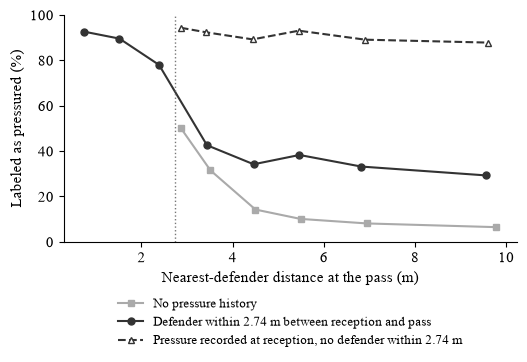

In [3]:
E = pd.read_csv(os.path.join(OUT, "pressure_events.csv.gz"))
X = E[E.label.isin(["P", "N"])].merge(pd.read_csv(os.path.join(OUT, "possession_exposure.csv.gz")), on=KEY) \
     .merge(pd.read_csv(os.path.join(OUT, "reception_labels.csv.gz")), on=KEY, how="left")
X["P"] = (X.label == "P").astype(int)
X["history"] = np.select([X.d_min < 2.74, X.init_pressure.eq("P")],
                         ["Defender within 2.74 m between reception and pass",
                          "Pressure recorded at reception, no defender within 2.74 m"],
                         "No pressure history")
bins = [0, 1, 2, 3, 4, 5, 6, 8, 12]
X["dbin"] = pd.cut(X.d_end, bins)
rate = X.pivot_table(index="dbin", columns="history", values="P", aggfunc="mean", observed=True) * 100
cnt = X.pivot_table(index="dbin", columns="history", values="P", aggfunc="size", observed=True)
xpos = X.pivot_table(index="dbin", columns="history", values="d_end", aggfunc="mean", observed=True)
rate, xpos = rate.where(cnt >= 50), xpos.where(cnt >= 50)
# same visual style as the companion abstract figure: Times New Roman, grayscale, no top/right spines
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11})
fig, ax = plt.subplots(figsize=(5.4, 3.9))
for col, c, ls, mk, mfc in [("No pressure history", "#aaaaaa", "-", "s", "#aaaaaa"),
                            ("Defender within 2.74 m between reception and pass", "#333333", "-", "o", "#333333"),
                            ("Pressure recorded at reception, no defender within 2.74 m", "#333333", "--", "^", "white")]:
    if col in rate:
        ax.plot(xpos[col], rate[col], marker=mk, ms=5, color=c, ls=ls, mfc=mfc, lw=1.5, label=col)
ax.axvline(2.74, ls=":", c="#777777", lw=1)
ax.set_xlabel("Nearest-defender distance at the pass (m)"); ax.set_ylabel("Labeled as pressured (%)")
ax.set_ylim(0, 100); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "abstract_v2_fig1.png"), dpi=300, bbox_inches="tight", pad_inches=0.05)
display(rate.round(3))
cnt